# Apartment List Time-on-Market as a Predictor of Apartment REIT Performance

## Project Overview

This notebook tests whether **Apartment List's metro-level Time on Market (TOM) measure** — the average days a rental listing remains active before being leased — contains predictive information about apartment REIT financial and stock-market performance.

**Five REITs are analysed** (UDR excluded: insufficient geographic granularity in its public supplemental disclosures):

| Ticker | Company | Primary Market Focus |
|--------|---------|----------------------|
| AVB | AvalonBay Communities | Coastal gateway (DC, NY, Boston, LA, Seattle, SF) |
| EQR | Equity Residential | Coastal gateway + Denver, Austin |
| CPT | Camden Property Trust | Sunbelt (Dallas, Atlanta, Houston, Phoenix) |
| ESS | Essex Property Trust | West Coast (LA, SF, Seattle, San Diego) |
| MAA | Mid-America Apartment | Sunbelt secondary markets |

**Four target variables are tested:**

1. **Revenue growth** — YoY change in quarterly Compustat total revenue *(core result)*
2. **IBES analyst surprise** — actual vs. consensus for EPS, SAL, FFO
3. **Announcement-window CAR** — abnormal return in a 3-day window around earnings
4. **Quarterly buy-and-hold return** — raw stock return over the following quarter

## Notebook Structure

| Section | Content |
|---------|--------|
| 0 | Setup: imports and configuration |
| 1 | WRDS data extraction (Compustat, IBES, CRSP) |
| 2 | Apartment List signal construction |
| 3 | Target variable construction |
| 4 | Baseline merge and OLS |
| 5 | Statistical inference helper functions |
| 6 | Eight-check robustness diagnostic suite |
| 7 | Full pipeline runner |


## Section 0.1 — Imports

Standard scientific Python stack. No project-specific logic here.

In [36]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from scipy import stats

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 120)
print("Imports OK")

Imports OK


## Section 0.2 — Configuration

**All project-level parameters live here.** Changing `TARGET_METRIC` and `LAG_QUARTERS` switches between the four dependent variables and the contemporaneous vs. leading-indicator specifications without touching any other cell.

| `TARGET_METRIC` | Description | Recommended `LAG_QUARTERS` |
|-----------------|-------------|----------------------------|
| `"revenue_growth"` | YoY Compustat revenue growth | 0 or 1 |
| `"ibes_surprise"` | IBES actual minus analyst consensus | 0 |
| `"car_announcement"` | Abnormal return around earnings announcement | 0 |
| `"quarterly_return"` | Buy-and-hold return over following quarter | 1 |

**REIT metro weights** are derived from each REIT's most recent public supplemental disclosure, mapping metro exposure to the Apartment List geography.

In [37]:
# ── File paths ─────────────────────────────────────────────────────────────
# Output files from Section 1 (WRDS extraction). Update paths if your working
# directory differs from where the CSVs were saved.
REIT_FINANCIALS_FILE  = "reit_financials.csv"
IBES_FILE             = "reit_ibes_surprise.csv"
STOCK_RETURNS_FILE    = "reit_daily_returns.csv"
AL_FILE               = "apartmentlist_time_on_market_metro.csv"

# ── WRDS extraction parameters ──────────────────────────────────────────────
TICKERS    = ["AVB", "EQR", "UDR", "CPT", "ESS", "MAA"]
START_DATE = "2015-01-01"
END_DATE   = "2025-12-31"

# ── Analysis parameters ─────────────────────────────────────────────────────
TARGET_METRIC      = "revenue_growth"  # "revenue_growth" | "ibes_surprise" |
                                       # "car_announcement" | "quarterly_return"
IBES_MEASURE       = "SAL"            # "SAL" | "EPS" | "FFO"
LAG_QUARTERS       = 1               # 0 = contemporaneous; 1 = one-quarter-ahead
EVENT_WINDOW_DAYS  = 1               # half-width of CAR window in calendar days

LOCATION_COL = "location_name"        # column in AL file holding the metro name

# Quarters excluded in the COVID-robustness check (Section 6, Check 3)
EXCLUDE_PERIOD_CHECK = [pd.Period(f"{y}Q{q}") for y in [2020, 2021] for q in [1, 2, 3, 4]]

# ── REIT metro exposure weights ─────────────────────────────────────────────
# Derived from each REIT's most recent public supplemental filing.
# Keys must match the 'location_name' column in the Apartment List metro file.
REIT_METRO_WEIGHTS = {
    "AVB": {
        "Washington-Arlington-Alexandria, DC-VA-MD-WV Metro Area": 0.14,
        "New York-Newark-Jersey City, NY-NJ-PA Metro Area":        0.13,
        "Boston-Cambridge-Newton, MA-NH Metro Area":               0.12,
        "Los Angeles-Long Beach-Anaheim, CA Metro Area":           0.09,
        "Seattle-Tacoma-Bellevue, WA Metro Area":                  0.09,
        "San Jose-Sunnyvale-Santa Clara, CA Metro Area":           0.08,
        "San Francisco-Oakland-Berkeley, CA Metro Area":           0.07,
    },
    "EQR": {
        "Washington-Arlington-Alexandria, DC-VA-MD-WV Metro Area": 0.14,
        "New York-Newark-Jersey City, NY-NJ-PA Metro Area":        0.13,
        "San Francisco-Oakland-Berkeley, CA Metro Area":           0.09,
        "Seattle-Tacoma-Bellevue, WA Metro Area":                  0.09,
        "Los Angeles-Long Beach-Anaheim, CA Metro Area":           0.08,
        "Boston-Cambridge-Newton, MA-NH Metro Area":               0.08,
        "Denver-Aurora-Lakewood, CO Metro Area":                   0.07,
        "Austin-Round Rock-Georgetown, TX Metro Area":             0.07,
    },
    "CPT": {
        "Dallas-Fort Worth-Arlington, TX Metro Area":              0.14,
        "Atlanta-Sandy Springs-Alpharetta, GA Metro Area":         0.12,
        "Houston-The Woodlands-Sugar Land, TX Metro Area":         0.11,
        "Denver-Aurora-Lakewood, CO Metro Area":                   0.09,
        "Phoenix-Mesa-Chandler, AZ Metro Area":                    0.09,
        "Washington-Arlington-Alexandria, DC-VA-MD-WV Metro Area": 0.07,
        "Tampa-St. Petersburg-Clearwater, FL Metro Area":          0.07,
        "Austin-Round Rock-Georgetown, TX Metro Area":             0.07,
        "Charlotte-Concord-Gastonia, NC-SC Metro Area":            0.07,
        "Nashville-Davidson--Murfreesboro--Franklin, TN Metro Area": 0.07,
        "Raleigh-Cary, NC Metro Area":                             0.07,
        "San Diego-Chula Vista-Carlsbad, CA Metro Area":           0.06,
        "Orlando-Kissimmee-Sanford, FL Metro Area":                0.05,
    },
    "ESS": {
        "Los Angeles-Long Beach-Anaheim, CA Metro Area":           0.27,
        "San Francisco-Oakland-Berkeley, CA Metro Area":           0.24,
        "Seattle-Tacoma-Bellevue, WA Metro Area":                  0.24,
        "San Jose-Sunnyvale-Santa Clara, CA Metro Area":           0.17,
        "San Diego-Chula Vista-Carlsbad, CA Metro Area":           0.08,
    },
    "MAA": {
        "Atlanta-Sandy Springs-Alpharetta, GA Metro Area":         0.12,
        "Dallas-Fort Worth-Arlington, TX Metro Area":              0.11,
        "Austin-Round Rock-Georgetown, TX Metro Area":             0.09,
        "Charlotte-Concord-Gastonia, NC-SC Metro Area":            0.08,
        "Tampa-St. Petersburg-Clearwater, FL Metro Area":          0.08,
        "Nashville-Davidson--Murfreesboro--Franklin, TN Metro Area": 0.07,
        "Raleigh-Cary, NC Metro Area":                             0.07,
        "Phoenix-Mesa-Chandler, AZ Metro Area":                    0.06,
        "Orlando-Kissimmee-Sanford, FL Metro Area":                0.06,
        "Washington-Arlington-Alexandria, DC-VA-MD-WV Metro Area": 0.05,
        "Richmond, VA Metro Area":                                 0.05,
        "Houston-The Woodlands-Sugar Land, TX Metro Area":         0.05,
        "Jacksonville, FL Metro Area":                             0.04,
        "Memphis, TN-MS-AR Metro Area":                            0.04,
        "Huntsville, AL Metro Area":                               0.03,
        "Greenville-Anderson, SC Metro Area":                      0.03,
        "Savannah, GA Metro Area":                                 0.02,
        "Fredericksburg, VA-MD Metro Area":                        0.02,
        "Birmingham-Hoover, AL Metro Area":                        0.02,
    },
}

print("Configuration loaded.")
print(f"  TARGET_METRIC = {TARGET_METRIC!r}  |  IBES_MEASURE = {IBES_MEASURE!r}")
print(f"  LAG_QUARTERS  = {LAG_QUARTERS}      |  EVENT_WINDOW_DAYS = {EVENT_WINDOW_DAYS}")
print(f"  REITs with weights: {list(REIT_METRO_WEIGHTS.keys())}")

Configuration loaded.
  TARGET_METRIC = 'revenue_growth'  |  IBES_MEASURE = 'SAL'
  LAG_QUARTERS  = 1      |  EVENT_WINDOW_DAYS = 1
  REITs with weights: ['AVB', 'EQR', 'CPT', 'ESS', 'MAA']


---
## Section 1 — WRDS Data Extraction

Three datasets are pulled from WRDS and saved as CSV files. If you already have these files, skip to Section 2.

| Dataset | WRDS table | Contents |
|---------|-----------|----------|
| Compustat | `comp.fundq` | Quarterly total revenue per REIT |
| IBES | `ibes.surpsum` | Actual vs. consensus surprise for EPS, SAL, FFO |
| CRSP | `crsp.dsf` + `crsp.dsi` | Daily returns + value-weighted market benchmark |

### Section 1.1 — Connect to WRDS

Requires a WRDS account and network access (on-campus or VPN).

In [38]:
!pip install wrds

In [39]:
import wrds
db = wrds.Connection()
print("Connected to WRDS")

Enter your WRDS username [root]:hermanthinnd
Enter your password:··········
WRDS recommends setting up a .pgpass file.
Create .pgpass file now [y/n]?: n
You can create this file yourself at any time with the create_pgpass_file() function.
Loading library list...
Done
Connected to WRDS


### Section 1.2 — Compustat: Quarterly Revenue

Pulls `revtq` (total revenue in USD millions) from `comp.fundq`. UDR is included in the pull but excluded from the signal analysis in Section 2.2 due to insufficient portfolio geographic detail.

In [40]:
tic_list_sql = ", ".join(f"'{t}'" for t in TICKERS)

financials_raw = db.raw_sql(f"""
    SELECT tic, datadate, fyearq, fqtr, revtq, conm
    FROM comp.fundq
    WHERE tic IN ({tic_list_sql})
      AND indfmt  = 'INDL'
      AND datafmt = 'STD'
      AND popsrc  = 'D'
      AND consol  = 'C'
      AND datadate BETWEEN '{START_DATE}' AND '{END_DATE}'
      AND revtq IS NOT NULL
    ORDER BY tic, datadate
""")

print(f"Pulled {len(financials_raw)} rows from Compustat fundq.")
print(financials_raw.groupby("tic").size().rename("n_quarters"))
financials_raw.to_csv(REIT_FINANCIALS_FILE, index=False)
print(f"Saved {REIT_FINANCIALS_FILE}")

Pulled 264 rows from Compustat fundq.
tic
AVB    44
CPT    44
EQR    44
ESS    44
MAA    44
UDR    44
Name: n_quarters, dtype: int64
Saved reit_financials.csv


### Section 1.3 — IBES: Analyst Surprise Data

Pre-computed actual-vs-consensus surprise from `ibes.surpsum`. Three measures are requested simultaneously and distinguished by the `measure` column:

- **EPS** — GAAP earnings per share
- **SAL** — Revenue/sales surprise (analogue to the Compustat revenue result)
- **FFO** — Funds From Operations (the REIT industry's preferred performance metric)

`fiscalp = 'QTR'` restricts to quarterly estimates.

In [41]:
cols = db.raw_sql("SELECT column_name FROM information_schema.columns WHERE table_schema = 'ibes' AND table_name = 'surpsum' ORDER BY ordinal_position")
print(cols["column_name"].tolist())

['ticker', 'oftic', 'measure', 'fiscalp', 'pyear', 'pmon', 'usfirm', 'anndats', 'actual', 'surpmean', 'surpstdev', 'suescore']


In [42]:
ibes_raw = db.raw_sql(f"""
    SELECT oftic, measure, pyear, pmon, anndats, actual, surpmean
    FROM ibes.surpsum
    WHERE oftic IN ({tic_list_sql})
      AND fiscalp  = 'QTR'
      AND measure  IN ('EPS', 'SAL', 'FFO')
      AND anndats BETWEEN '{START_DATE}' AND '{END_DATE}'
    ORDER BY oftic, measure, pyear, pmon
""")

ibes_raw = ibes_raw.rename(columns={"surpmean": "surprise"})

print(f"Pulled {len(ibes_raw)} rows from IBES.")
print(ibes_raw.groupby("measure").size().rename("n_rows"))
ibes_raw.to_csv(IBES_FILE, index=False)
print(f"Saved {IBES_FILE}")

Pulled 786 rows from IBES.
measure
EPS    262
FFO    262
SAL    262
Name: n_rows, dtype: int64
Saved reit_ibes_surprise.csv


### Section 1.4 — CRSP: Daily Stock Returns and Market Benchmark

Daily returns from `crsp.dsf`; CRSP value-weighted market return from `crsp.dsi`.

**Critical implementation note — ticker date-range join:**
CRSP identifies securities by PERMNO, not ticker. Tickers are reused across companies over decades (e.g. 'CPT' appeared under at least two other companies before Camden Property Trust; UDR has had several historical ticker names). Joining on PERMNO alone without restricting to the date range each ticker was valid produces severe row duplication. The join uses `a.date BETWEEN b.namedt AND b.nameenddt` to prevent this.

A sanity-check print confirms rows per ticker are approximately equal (~252/year), not multiplied by the number of historical ticker-name segments.

In [43]:
# Show full PERMNO/ticker history for transparency.
# CRSP tickers are reused across companies over decades; the date-range join
# below (a.date BETWEEN b.namedt AND b.nameenddt) ensures each return row is
# matched only to the ticker that was actually valid on that specific date.
# Omitting this restriction causes severe row duplication in the output.
permno_history = db.raw_sql(f"""
    SELECT DISTINCT permno, ticker, namedt, nameenddt
    FROM crsp.stocknames
    WHERE ticker IN ({tic_list_sql})
    ORDER BY ticker, namedt
""")
print("PERMNO / ticker history (for transparency — only date-valid rows used in main join):")
print(permno_history.to_string(index=False))

# Main pull: date-range-restricted join prevents ticker-reuse duplication
daily_raw = db.raw_sql(f"""
    SELECT a.permno, a.date, a.ret, b.ticker
    FROM crsp.dsf a
    JOIN crsp.stocknames b
      ON  a.permno = b.permno
      AND a.date BETWEEN b.namedt AND b.nameenddt
    WHERE b.ticker IN ({tic_list_sql})
      AND a.date BETWEEN '{START_DATE}' AND '{END_DATE}'
""")

market_raw = db.raw_sql(f"""
    SELECT date, vwretd
    FROM crsp.dsi
    WHERE date BETWEEN '{START_DATE}' AND '{END_DATE}'
""")

daily_raw = daily_raw.rename(columns={"ticker": "tic"}).merge(market_raw, on="date", how="left")

print(f"\nPulled {len(daily_raw)} daily return rows.")
print("\nRows per ticker (should be ~equal, ~252 × years in range — NOT multiplied by")
print("the number of historical ticker-name segments):")
print(daily_raw.groupby("tic").size().rename("n_days"))

daily_raw.to_csv(STOCK_RETURNS_FILE, index=False)
print(f"\nSaved {STOCK_RETURNS_FILE}")
db.close()

PERMNO / ticker history (for transparency — only date-valid rows used in main join):
 permno ticker     namedt  nameenddt
  80381    AVB 1998-06-05 1998-10-04
  80381    AVB 1998-10-05 2024-12-31
  45452    CPT 1967-12-05 1968-01-01
  45452    CPT 1968-01-02 1973-05-25
  10923    CPT 1988-11-01 1990-10-05
  79452    CPT 1993-07-22 2024-12-31
  79547    EQR 1993-08-12 2002-05-15
  79547    EQR 2002-05-16 2024-12-31
  80681    ESS 1994-06-07 2024-12-31
  80183    MAA 1994-01-28 2024-12-31
  59300    UDR 1990-05-07 1994-06-30
  59300    UDR 1994-07-01 2007-03-14
  59300    UDR 2007-03-15 2024-12-31

Pulled 15096 daily return rows.

Rows per ticker (should be ~equal, ~252 × years in range — NOT multiplied by
the number of historical ticker-name segments):
tic
AVB    2516
CPT    2516
EQR    2516
ESS    2516
MAA    2516
UDR    2516
Name: n_days, dtype: int64

Saved reit_daily_returns.csv


---
## Section 2 — Apartment List Signal Construction

The raw Apartment List file contains monthly TOM values for ~200 US metros. This section collapses that to a single REIT-specific composite per ticker per quarter using portfolio-exposure-weighted averages.

### Section 2.1 — Load Apartment List Metro Data

Handles both wide format (one column per month) and long format (one row per metro-month). Output: long-format `[location_name, date (Period M), time_on_market]`.

In [44]:
import pandas as pd
print(pd.read_csv(AL_FILE).columns.tolist())

['location_name', 'location_type', 'location_fips_code', 'population', 'state', 'county', 'metro', '2019_01', '2019_02', '2019_03', '2019_04', '2019_05', '2019_06', '2019_07', '2019_08', '2019_09', '2019_10', '2019_11', '2019_12', '2020_01', '2020_02', '2020_03', '2020_04', '2020_05', '2020_06', '2020_07', '2020_08', '2020_09', '2020_10', '2020_11', '2020_12', '2021_01', '2021_02', '2021_03', '2021_04', '2021_05', '2021_06', '2021_07', '2021_08', '2021_09', '2021_10', '2021_11', '2021_12', '2022_01', '2022_02', '2022_03', '2022_04', '2022_05', '2022_06', '2022_07', '2022_08', '2022_09', '2022_10', '2022_11', '2022_12', '2023_01', '2023_02', '2023_03', '2023_04', '2023_05', '2023_06', '2023_07', '2023_08', '2023_09', '2023_10', '2023_11', '2023_12', '2024_01', '2024_02', '2024_03', '2024_04', '2024_05', '2024_06', '2024_07', '2024_08', '2024_09', '2024_10', '2024_11', '2024_12', '2025_01', '2025_02', '2025_03', '2025_04', '2025_05', '2025_06', '2025_07', '2025_08', '2025_09', '2025_10',

In [45]:
def load_apartmentlist_metro_file(path, location_col):
    raw = pd.read_csv(path)
    # Identify month columns by pattern YYYY_MM
    month_cols = [c for c in raw.columns if len(c) == 7 and c[4] == '_' and c[:4].isdigit()]
    print(f"[loader] Wide format: {len(month_cols)} month columns, {len(raw)} locations.")
    df = raw.melt(id_vars=[location_col], value_vars=month_cols,
                  var_name="date_str", value_name="time_on_market")
    df["date"] = pd.to_datetime(df["date_str"].str.replace("_", "-") + "-01").dt.to_period("M")
    df = df[[location_col, "date", "time_on_market"]].dropna()
    df["time_on_market"] = pd.to_numeric(df["time_on_market"], errors="coerce")
    return df.dropna(subset=["time_on_market"])


al_long = load_apartmentlist_metro_file(AL_FILE, LOCATION_COL)
print(f"Loaded {len(al_long)} metro-month rows across "
      f"{al_long['date'].nunique()} months and "
      f"{al_long[LOCATION_COL].nunique()} metros.")
print(al_long.head(3).to_string(index=False))

[loader] Wide format: 89 month columns, 200 locations.
Loaded 17800 metro-month rows across 89 months and 200 metros.
location_name    date  time_on_market
United States 2019-01            33.3
   California 2019-01            29.7
        Texas 2019-01            38.0


### Section 2.2 — Build REIT-Exposure-Weighted Monthly Composite

For each REIT and each month, the composite is the weighted average TOM across the metros in that REIT's portfolio, weighted by the exposure fractions in `REIT_METRO_WEIGHTS`. Metros absent from the Apartment List file are warned and dropped; weights are not re-normalised after dropping missing metros.

[warn] MAA: metros not in AL file (skipped): {'Richmond, VA Metro Area', 'Greenville-Anderson, SC Metro Area', 'Birmingham-Hoover, AL Metro Area', 'Huntsville, AL Metro Area', 'Memphis, TN-MS-AR Metro Area', 'Savannah, GA Metro Area', 'Fredericksburg, VA-MD Metro Area'}

Monthly composite: 445 REIT-month rows, 5 REITs.


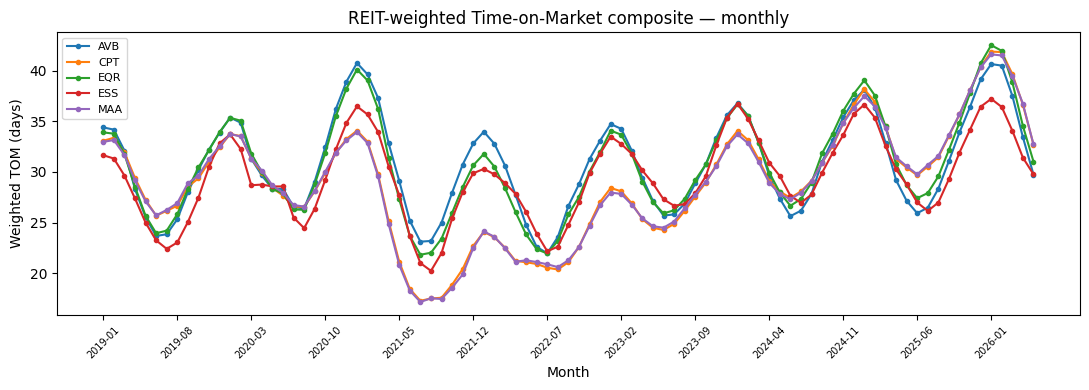

In [46]:
def build_reit_weighted_composite(al_long, location_col, reit_weights):
    # Builds a monthly REIT-specific TOM composite via portfolio-exposure-weighted average.
    # Metros in the weights table but absent from the AL file are warned and skipped.
    rows = []
    for tic, weights in reit_weights.items():
        all_metros   = set(weights.keys())
        avail_metros = set(al_long[location_col].unique())
        missing      = all_metros - avail_metros
        if missing:
            print(f"[warn] {tic}: metros not in AL file (skipped): {missing}")

        usable = {m: w for m, w in weights.items() if m in avail_metros}
        if not usable:
            print(f"[error] {tic}: no metros matched — REIT excluded entirely.")
            continue

        subset = al_long[al_long[location_col].isin(usable)].copy()
        subset["weight"]      = subset[location_col].map(usable)
        subset["weighted_tom"] = subset["time_on_market"] * subset["weight"]
        monthly = (subset.groupby("date")
                         .apply(lambda g: g["weighted_tom"].sum() / g["weight"].sum(), include_groups=False)
                         .reset_index(name="composite"))
        monthly["tic"] = tic
        rows.append(monthly)

    return pd.concat(rows, ignore_index=True)[["tic", "date", "composite"]]


composite_monthly = build_reit_weighted_composite(al_long, LOCATION_COL, REIT_METRO_WEIGHTS)
print(f"\nMonthly composite: {len(composite_monthly)} REIT-month rows, "
      f"{composite_monthly['tic'].nunique()} REITs.")

# Time-series plot of all REIT composites
fig, ax = plt.subplots(figsize=(11, 4))
for tic, grp in composite_monthly.groupby("tic"):
    dates = [str(d) for d in grp["date"]]
    ax.plot(dates, grp["composite"], marker="o", markersize=3, label=tic)
ax.set_xlabel("Month")
ax.set_ylabel("Weighted TOM (days)")
ax.set_title("REIT-weighted Time-on-Market composite — monthly")
ax.legend(fontsize=8)
step = max(1, len(dates) // 12)
ax.set_xticks(range(0, len(dates), step))
ax.set_xticklabels(dates[::step], rotation=45, fontsize=7)
plt.tight_layout()
plt.show()

### Section 2.3 — Aggregate Monthly Composite to Quarterly

Simple average of the three months within each calendar quarter. Output: `[tic, quarter (Period Q), composite]`.

In [47]:
def monthly_to_quarterly(composite_monthly):
    # Converts the monthly REIT composite to a quarterly average using calendar quarters.
    df = composite_monthly.copy()
    df["quarter"] = df["date"].dt.to_timestamp().dt.to_period("Q")
    return (df.groupby(["tic", "quarter"])["composite"]
              .mean()
              .reset_index())


composite_q = monthly_to_quarterly(composite_monthly)
print(f"Quarterly composite: {len(composite_q)} REIT-quarter rows.")
print(composite_q.pivot(index="quarter", columns="tic", values="composite").tail(6).round(1))

Quarterly composite: 150 REIT-quarter rows.
tic       AVB   CPT   EQR   ESS   MAA
quarter                              
2025Q1   35.8  36.5  37.0  34.9  36.1
2025Q2   27.4  30.5  29.0  28.7  30.6
2025Q3   28.6  31.8  29.9  27.5  32.0
2025Q4   36.5  38.0  37.8  34.2  38.0
2026Q1   39.5  41.1  41.1  35.9  40.9
2026Q2   31.6  34.7  32.8  30.6  34.7


---
## Section 3 — Target Variable Construction

All four target metrics are defined here. Each function returns `[tic, quarter, target]` so the merge logic in Section 4 is identical regardless of which metric is selected. `build_target()` dispatches to the appropriate loader based on `TARGET_METRIC`.

**Revenue growth note:** `revtq` is *total* revenue, not same-store. Acquisitions, developments, and dispositions add noise beyond rent and occupancy. Same-store revenue (hand-collected from REIT supplementals) is identified as the single highest-value data improvement for future work.

**CAR note:** the composite for quarter t is fully known before that quarter's earnings announcement, so `LAG_QUARTERS=0` is the correct temporal alignment.

**Quarterly return note:** `LAG_QUARTERS=1` is the correct alignment — observe the composite at end of quarter t, then hold the stock in quarter t+1.

In [48]:
def load_reit_financials(path):
    # Loads Compustat revenue and computes YoY growth using the same fiscal quarter one year prior.
    # UDR is excluded: insufficient metro granularity for composite construction.
    fin = pd.read_csv(path, parse_dates=["datadate"])
    fin["quarter"] = fin["datadate"].dt.to_period("Q")
    fin = fin.sort_values(["tic", "quarter"])
    fin["revenue_lag4"]      = fin.groupby("tic")["revtq"].shift(4)
    fin["revenue_growth_yoy"] = (fin["revtq"] - fin["revenue_lag4"]) / fin["revenue_lag4"].abs()
    fin = fin[fin["tic"] != "UDR"].dropna(subset=["revenue_growth_yoy"])
    return fin[["tic", "quarter", "revtq", "revenue_growth_yoy"]]


def load_ibes_surprise(path, measure):
    # Filters IBES to the requested measure (SAL/EPS/FFO) and maps fiscal period to calendar quarter.
    # When a ticker-quarter has duplicate rows, keeps the most recent announcement date.
    ibes = pd.read_csv(path)
    ibes = ibes[ibes["measure"] == measure].copy()
    if ibes.empty:
        raise ValueError(f"No rows for measure='{measure}' in {path}.")
    ibes = ibes.rename(columns={"oftic": "tic"})
    ibes["fpedats"] = pd.to_datetime(
        ibes["pyear"].astype(int).astype(str) + "-" +
        ibes["pmon"].astype(int).astype(str).str.zfill(2) + "-01"
    )
    ibes["quarter"] = ibes["fpedats"].dt.to_period("Q")
    ibes = ibes.sort_values("anndats").drop_duplicates(["tic", "quarter"], keep="last")
    return ibes[["tic", "quarter", "surprise"]]


def load_announcement_dates(ibes_path):
    # Extracts one announcement date per (tic, quarter) from the EPS rows of the IBES file.
    # All three measures (EPS, SAL, FFO) are released in the same press release, so EPS
    # anndats reliably identifies the announcement date for all three.
    ibes = pd.read_csv(ibes_path)
    eps  = ibes[ibes["measure"] == "EPS"].copy()
    if eps.empty:
        raise ValueError("No EPS rows in IBES file — needed to extract announcement dates.")
    eps["anndats"]  = pd.to_datetime(eps["anndats"])
    eps["fpedats"]  = pd.to_datetime(
        eps["pyear"].astype(int).astype(str) + "-" +
        eps["pmon"].astype(int).astype(str).str.zfill(2) + "-01"
    )
    eps["quarter"] = eps["fpedats"].dt.to_period("Q")
    eps = eps.rename(columns={"oftic": "tic"})
    eps = eps.sort_values("anndats").drop_duplicates(["tic", "quarter"], keep="last")
    return eps[["tic", "quarter", "anndats"]]


def load_daily_returns(path):
    # Loads CRSP daily return file and computes market-adjusted abnormal return per day.
    # abnormal_ret = individual stock return minus CRSP value-weighted market return.
    daily = pd.read_csv(path, parse_dates=["date"])
    daily["abnormal_ret"] = daily["ret"] - daily["vwretd"]
    return daily


def compute_car_around_announcement(daily, announce_dates, window_days=1):
    # Cumulative abnormal return in a [-window_days, +window_days] calendar-day window.
    # Uses calendar days (not trading days) — a ±1 day window captures 2-3 trading days
    # depending on weekends and holidays, which is appropriate for a short event study.
    rows = []
    for _, arow in announce_dates.iterrows():
        tic, quarter, anndats = arow["tic"], arow["quarter"], arow["anndats"]
        lo     = anndats - pd.Timedelta(days=window_days)
        hi     = anndats + pd.Timedelta(days=window_days)
        window = daily[(daily["tic"] == tic) & (daily["date"] >= lo) & (daily["date"] <= hi)]
        if window.empty:
            continue
        rows.append({"tic": tic, "quarter": quarter, "target": window["abnormal_ret"].sum()})
    return pd.DataFrame(rows)


def compute_quarterly_return(daily):
    # Computes compounded buy-and-hold stock return per (tic, calendar quarter).
    df = daily.copy()
    df["quarter"] = df["date"].dt.to_period("Q")
    return (df.groupby(["tic", "quarter"])["ret"]
              .apply(lambda r: (1 + r).prod() - 1)
              .reset_index()
              .rename(columns={"ret": "target"}))


def build_target(financials_path, target_metric, ibes_path=None, ibes_measure="SAL",
                 stock_returns_path=None, event_window_days=1):
    # Dispatches to the appropriate loader and returns a standardised [tic, quarter, target]
    # dataframe plus a human-readable label for use in plots and print statements.
    fin = load_reit_financials(financials_path)

    if target_metric == "ibes_surprise":
        ibes   = load_ibes_surprise(ibes_path, ibes_measure)
        merged = fin.merge(ibes, on=["tic", "quarter"], how="inner")
        merged["target"] = merged["surprise"]
        names  = {"SAL": "revenue/sales", "EPS": "GAAP EPS", "FFO": "FFO"}
        label  = f"IBES {names.get(ibes_measure, ibes_measure)} surprise (actual − consensus)"
        print(f"[target] IBES {ibes_measure}: {len(merged)} matched REIT-quarter rows.")
        return merged[["tic", "quarter", "target"]], label

    if target_metric == "car_announcement":
        daily  = load_daily_returns(stock_returns_path)
        ann    = load_announcement_dates(ibes_path)
        car    = compute_car_around_announcement(daily, ann, event_window_days)
        label  = (f"Cumulative abnormal return, "
                  f"[−{event_window_days},+{event_window_days}] days around announcement")
        print(f"[target] CAR (±{event_window_days} day): {len(car)} REIT-quarter rows.")
        print("[target] NOTE: LAG_QUARTERS=0 is the correct alignment — the composite for")
        print("         quarter t is fully known before that quarter's earnings announcement.")
        return car[["tic", "quarter", "target"]], label

    if target_metric == "quarterly_return":
        daily  = load_daily_returns(stock_returns_path)
        qret   = compute_quarterly_return(daily)
        label  = "Quarterly buy-and-hold stock return"
        print(f"[target] Quarterly return: {len(qret)} REIT-quarter rows.")
        print("[target] NOTE: LAG_QUARTERS=1 is the correct alignment — observe composite")
        print("         in quarter t, hold the stock in quarter t+1.")
        return qret[["tic", "quarter", "target"]], label

    # Default: revenue growth
    fin["target"] = fin["revenue_growth_yoy"]
    label = "YoY revenue growth (Compustat)"
    print(f"[target] Revenue growth: {len(fin)} REIT-quarter rows.")
    return fin[["tic", "quarter", "target"]], label


# Build the selected target based on configuration
target_df, target_label = build_target(
    REIT_FINANCIALS_FILE, TARGET_METRIC,
    IBES_FILE, IBES_MEASURE,
    STOCK_RETURNS_FILE, EVENT_WINDOW_DAYS,
)
print(f"\nTarget: {target_label}")
print(target_df.head(6).to_string(index=False))

[target] Revenue growth: 200 REIT-quarter rows.

Target: YoY revenue growth (Compustat)
tic quarter   target
AVB  2016Q1 0.082253
AVB  2016Q2 0.123480
AVB  2016Q3 0.040239
AVB  2016Q4 0.096463
AVB  2017Q1 0.044244
AVB  2017Q2 0.004157


---
## Section 4 — Signal-Target Merge and Baseline Analysis

### Section 4.1 — Merge with Optional Lag Shift

When `LAG_QUARTERS > 0`, the target's quarter index is shifted back before merging so that composite[t] is paired with target[t + LAG_QUARTERS].

**Note:** `merged['quarter']` always records the composite's observation quarter, not the realised outcome quarter. This distinction matters for the COVID exclusion in Check 3 and the outlier display in Check 5.

In [49]:
def run_validation(composite_q, fin, lag_quarters, target_label):
    # Merges quarterly composite with target variable.
    # When lag_quarters > 0, the target's quarter index is shifted back by that many quarters
    # so composite[t] aligns with target[t + lag_quarters] — the leading-indicator specification.
    if lag_quarters == 0:
        merged = composite_q.merge(fin, on=["tic", "quarter"], how="inner")
    else:
        fin_shifted = fin.copy()
        fin_shifted["quarter"] = fin_shifted["quarter"] - lag_quarters
        merged = composite_q.merge(fin_shifted, on=["tic", "quarter"], how="inner")

    merged = merged.dropna(subset=["composite", "target"])
    if len(merged) < 5:
        raise ValueError(
            f"Only {len(merged)} usable observations after merging. "
            "Check date ranges and metro weight mapping."
        )

    slope, intercept, r_val, p_val, _ = stats.linregress(merged["composite"], merged["target"])
    lag_str = f"(lag = {lag_quarters}Q)" if lag_quarters else "(contemporaneous)"
    print(f"[result] Target: {target_label} {lag_str}")
    print(f"[result] n = {len(merged)} REIT-quarter observations")
    print(f"[result] r = {r_val:.3f}  |  r² = {r_val**2:.3f}")
    print(f"[result] slope = {slope:.5f}  |  p = {p_val:.4f}")
    return merged, slope, intercept


merged, baseline_slope, baseline_intercept = run_validation(
    composite_q, target_df, LAG_QUARTERS, target_label
)

[result] Target: YoY revenue growth (Compustat) (lag = 1Q)
[result] n = 135 REIT-quarter observations
[result] r = -0.406  |  r² = 0.165
[result] slope = -0.00662  |  p = 0.0000


### Section 4.2 — Scatter Plot and Pooled OLS

Visual check of the signal-target relationship. The red line is the pooled OLS fit. Because cross-REIT correlation is high (0.71-1.00), the fit treats observations as more independent than they are. Fixed-effects and clustered specifications in Section 6 correct for this.

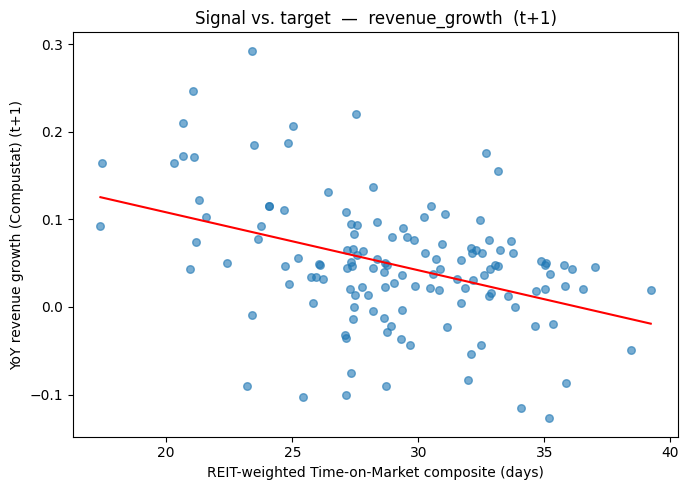

In [50]:
lag_str = f"(t+{LAG_QUARTERS})" if LAG_QUARTERS else "(contemporaneous)"

fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(merged["composite"], merged["target"], alpha=0.6, s=30)
x_vals = np.linspace(merged["composite"].min(), merged["composite"].max(), 100)
ax.plot(x_vals, baseline_intercept + baseline_slope * x_vals, color="red", lw=1.5)
ax.set_xlabel("REIT-weighted Time-on-Market composite (days)")
ax.set_ylabel(f"{target_label} {lag_str}")
ax.set_title(f"Signal vs. target  —  {TARGET_METRIC}  {lag_str}")
plt.tight_layout()
plt.show()

---
## Section 5 — Statistical Inference Helper Functions

### Section 5.1 — Cluster-Robust OLS and Driscoll-Kraay SE

**`cluster_robust_ols`** implements the sandwich estimator clustered by quarter. Allows arbitrary within-quarter correlation; assumes independence across quarters. Uses the small-cluster correction $(G/(G-1))\cdot((N-1)/(N-K))$.

**`driscoll_kraay_ols`** (1998) produces SEs robust to serial autocorrelation and cross-sectional dependence simultaneously — the theoretically preferred method for panels with few cross-sectional units (here N=5). Setting `maxlags=0` recovers HC-robust OLS, which was verified to agree closely with quarter-clustered results on balanced panels (internal consistency check).

In [51]:
def cluster_robust_ols(x, y, clusters):
    # OLS with sandwich standard errors clustered by the 'clusters' variable (typically quarter).
    # Allows arbitrary within-cluster correlation; assumes independence across clusters.
    # Uses a small-cluster degrees-of-freedom correction: (G/(G-1)) * ((N-1)/(N-K)).
    xv, yv = x.values.reshape(-1, 1), y.values
    n      = len(yv)
    X      = np.column_stack([np.ones(n), xv])
    beta   = np.linalg.lstsq(X, yv, rcond=None)[0]
    resid  = yv - X @ beta

    cluster_ids     = clusters.values
    unique_clusters = np.unique(cluster_ids)
    G, K            = len(unique_clusters), X.shape[1]

    meat = np.zeros((K, K))
    for c in unique_clusters:
        mask  = cluster_ids == c
        score = X[mask].T @ resid[mask]
        meat += np.outer(score, score)

    XtX_inv    = np.linalg.inv(X.T @ X)
    correction = (G / (G - 1)) * ((n - 1) / (n - K))
    V          = correction * XtX_inv @ meat @ XtX_inv

    se_slope = np.sqrt(V[1, 1])
    t_slope  = beta[1] / se_slope
    p_slope  = 2 * stats.t.sf(abs(t_slope), df=G - 1)
    return {"slope": beta[1], "intercept": beta[0], "se_slope": se_slope,
            "t_slope": t_slope, "p_slope": p_slope, "n": n, "n_clusters": G}


def driscoll_kraay_ols(x, y, time_index, maxlags=4):
    # OLS with Driscoll-Kraay (1998) standard errors, robust to both serial autocorrelation
    # and cross-sectional dependence simultaneously. Recommended when N is small (here N=5).
    # maxlags controls the Newey-West bandwidth; setting maxlags=0 recovers HC-robust OLS.
    xv, yv  = x.values, y.values
    n       = len(yv)
    X       = np.column_stack([np.ones(n), xv])
    beta    = np.linalg.lstsq(X, yv, rcond=None)[0]
    resid   = yv - X @ beta

    times = pd.Categorical(time_index).codes
    T, K  = len(np.unique(times)), X.shape[1]

    scores = np.zeros((T, K))
    for i, t in enumerate(times):
        scores[t] += X[i] * resid[i]

    S = scores.T @ scores
    for h in range(1, maxlags + 1):
        gamma = scores[h:].T @ scores[:-h]
        w     = 1 - h / (maxlags + 1)
        S    += w * (gamma + gamma.T)

    XtX_inv  = np.linalg.inv(X.T @ X)
    V        = (T / (T - K)) * XtX_inv @ S @ XtX_inv
    se_slope = np.sqrt(V[1, 1])
    t_slope  = beta[1] / se_slope
    p_slope  = 2 * stats.t.sf(abs(t_slope), df=T - 1)
    return {"slope": beta[1], "intercept": beta[0], "se_slope": se_slope,
            "t_slope": t_slope, "p_slope": p_slope, "n": n, "n_periods": T}


print("cluster_robust_ols and driscoll_kraay_ols defined.")

cluster_robust_ols and driscoll_kraay_ols defined.


### Section 5.2 — Panel Fixed-Effects Transformations and PCA

**`within_transform`** removes REIT fixed effects by demeaning within each REIT.

**`two_way_within_transform`** removes REIT and quarter fixed effects simultaneously via double demeaning: $x_{it}^* = x_{it} - \bar{x}_i - \bar{x}_t + \bar{x}$. Only within-REIT, within-quarter cross-sectional variation remains.

**`decompose_common_factor`** applies SVD to the composite matrix and returns per-REIT residuals after removing the leading shared factor(s). The two-factor version was discarded: it produced false positives on synthetic null data at N=5, a structural inferential limit not fixable with better code.

**`composite_correlation_matrix`** returns pairwise Pearson correlations between all REIT composites — the diagnostic motivating the two-way FE and PCA checks.

In [52]:
def within_transform(df, entity_col, cols):
    # Removes REIT fixed effects by demeaning each variable within each REIT.
    # After transformation, the regression uses only within-REIT time-series variation.
    out = df.copy()
    for c in cols:
        out[c] = out[c] - out.groupby(entity_col)[c].transform("mean")
    return out


def two_way_within_transform(df, entity_col, time_col, cols):
    # Removes both REIT and quarter fixed effects simultaneously via double demeaning:
    # x_demeaned = x - entity_mean - time_mean + grand_mean
    # After transformation, only within-REIT, within-quarter cross-sectional variation remains.
    # Any variation shared by all REITs in a given quarter is removed entirely.
    out = df.copy()
    for c in cols:
        entity_mean = out.groupby(entity_col)[c].transform("mean")
        time_mean   = out.groupby(time_col)[c].transform("mean")
        out[c]      = out[c] - entity_mean - time_mean + out[c].mean()
    return out


def decompose_common_factor(composite_q, n_factors=1):
    # PCA of the REIT composite matrix. Extracts the leading n_factors principal components
    # (the shared "national" or "regional" factors) and returns per-REIT residuals.
    #
    # IMPORTANT CAVEAT: a two-factor version (n_factors=2) was tested during development
    # and discarded — it produced false positives on synthetic null data because removing
    # 2 estimated factors from N=5 REITs leaves too few independent dimensions for
    # reliable inference. Only the single-factor (n_factors=1) residual is reported.
    wide      = composite_q.pivot(index="quarter", columns="tic", values="composite").dropna()
    X         = wide.values
    X_c       = X - X.mean(axis=0)
    U, S, Vt  = np.linalg.svd(X_c, full_matrices=False)
    var_expl  = (S ** 2) / np.sum(S ** 2)

    pct_var_pc1 = var_expl[0]
    pct_var_pc2 = var_expl[1] if len(var_expl) > 1 else 0.0

    loadings_df = pd.DataFrame({
        "tic":         wide.columns,
        "pc1_loading": Vt[0, :],
        "pc2_loading": Vt[1, :] if Vt.shape[0] > 1 else np.zeros(len(wide.columns)),
    })

    k             = min(n_factors, U.shape[1])
    factor_scores = U[:, :k] * S[:k]
    residuals     = pd.DataFrame(index=wide.index, columns=wide.columns, dtype=float)
    for j, tic in enumerate(wide.columns):
        y              = X_c[:, j]
        beta, *_       = np.linalg.lstsq(factor_scores, y, rcond=None)
        residuals[tic] = y - factor_scores @ beta

    residual_long = (residuals.reset_index()
                              .melt(id_vars="quarter", var_name="tic",
                                    value_name="residual_composite"))
    return residual_long, pct_var_pc1, pct_var_pc2, loadings_df


def composite_correlation_matrix(composite_q):
    # Pairwise Pearson correlation between all REIT quarterly composites.
    # High values (0.71-1.00 in our data) indicate the REITs primarily observe
    # a shared national apartment-market cycle through slightly different portfolio lenses.
    wide = composite_q.pivot(index="quarter", columns="tic", values="composite")
    return wide.corr()


print("Panel transformation and PCA helpers defined.")

Panel transformation and PCA helpers defined.


---
## Section 6 — Robustness Diagnostic Suite

Each check is an independent cell and can be re-run individually. All checks share `merged` from Section 4.1 and helpers from Section 5.

| Check | Test | Failure mode addressed |
|-------|------|------------------------|
| Diag. | Cross-REIT correlation matrix | Is the panel effectively one observation? |
| 1 | Pooled OLS + clustered SE | Inflated pooled significance |
| 2 | REIT FE + clustered SE | Between-REIT baseline differences |
| 3 | Ex-COVID (2020Q1-2021Q4) | Result driven by pandemic disruption |
| 4 | Driscoll-Kraay SE | Serial + cross-sectional dependence |
| 5 | Outlier diagnostic | Result driven by a handful of extreme quarters |
| 6 | Leave-one-REIT-out | Result driven by a single firm |
| 7 | REIT + quarter two-way FE | Result driven by shared national cycle |
| 8 | PCA factor decomposition | National vs. REIT-specific variation |

### Diagnostic — Cross-REIT Composite Correlation

Pairwise Pearson correlations between all five REIT quarterly composites. Values of 0.71-1.00 in this data signal a dominant shared national factor, meaning the REITs are not effectively independent observations. This directly motivates Checks 7 and 8.

In [53]:
# ── DIAGNOSTIC: Cross-REIT composite correlation matrix ─────────────────────
corr_mat = composite_correlation_matrix(composite_q)
print("Cross-REIT composite correlation matrix:")
print("(values 0.71-1.00 in this data signal a dominant shared national factor)")
print(corr_mat.round(2))

Cross-REIT composite correlation matrix:
(values 0.71-1.00 in this data signal a dominant shared national factor)
tic   AVB   CPT   EQR   ESS   MAA
tic                              
AVB  1.00  0.75  0.98  0.94  0.74
CPT  0.75  1.00  0.87  0.79  1.00
EQR  0.98  0.87  1.00  0.95  0.86
ESS  0.94  0.79  0.95  1.00  0.78
MAA  0.74  1.00  0.86  0.78  1.00


### Check 1 — Pooled OLS with Quarter-Clustered SE

The most permissive specification. Clusters by quarter to allow within-quarter cross-REIT correlation but does not remove REIT-level baseline differences. Check 2 is the more credible primary test.

In [54]:
cr1 = cluster_robust_ols(merged["composite"], merged["target"],
                          merged["quarter"].astype(str))
print("[Check 1] Pooled OLS with quarter-clustered SE")
print(f"  n = {cr1['n']},  n_clusters = {cr1['n_clusters']}")
print(f"  slope = {cr1['slope']:.5f},  SE = {cr1['se_slope']:.5f},  "
      f"t = {cr1['t_slope']:.2f},  p = {cr1['p_slope']:.4f}")

[Check 1] Pooled OLS with quarter-clustered SE
  n = 135,  n_clusters = 27
  slope = -0.00662,  SE = 0.00142,  t = -4.65,  p = 0.0001


### Check 2 — REIT Fixed Effects + Clustered SE

The most important single test. Within-REIT demeaning removes all time-invariant REIT differences, reducing the question to: does *this* REIT's composite being above *its own* historical average predict *its own* revenue growth being above its average?

In [55]:
within = within_transform(merged, "tic", ["composite", "target"])

slope_fe, _, r_fe, p_fe, _ = stats.linregress(within["composite"], within["target"])
print("[Check 2] REIT fixed effects (within-REIT demeaning)")
print(f"  Naive within-FE OLS:   slope = {slope_fe:.5f},  r = {r_fe:.3f},  p = {p_fe:.4f}")

cr2 = cluster_robust_ols(within["composite"], within["target"],
                          merged["quarter"].astype(str))
print(f"  Within-FE + clustered: slope = {cr2['slope']:.5f},  SE = {cr2['se_slope']:.5f},  "
      f"t = {cr2['t_slope']:.2f},  p = {cr2['p_slope']:.4f}")

[Check 2] REIT fixed effects (within-REIT demeaning)
  Naive within-FE OLS:   slope = -0.00643,  r = -0.392,  p = 0.0000
  Within-FE + clustered: slope = -0.00643,  SE = 0.00148,  t = -4.33,  p = 0.0002


### Check 3 — Pandemic-Period Exclusion (2020Q1-2021Q4)

Re-runs REIT FE excluding the COVID shock, to confirm the result holds outside the pandemic period.

**Critical implementation note:** the exclusion filters on the *realised outcome quarter* (`merged['quarter'] + LAG_QUARTERS`), not the composite's observation quarter. Filtering on the composite quarter silently leaves crash-period outcomes in the sample for any lagged specification, which would invalidate the check.

In [56]:
# CRITICAL: merged["quarter"] is always the COMPOSITE's quarter (never itself shifted).
# The target's realised outcome quarter = merged["quarter"] + LAG_QUARTERS.
# Filtering the exclusion on the wrong quarter would silently leave pandemic-period
# outcomes in the sample for any lagged specification.
realized_quarter  = merged["quarter"] + LAG_QUARTERS
exclude_q_strings = [str(q) for q in EXCLUDE_PERIOD_CHECK]
sub_excovid       = merged[~realized_quarter.astype(str).isin(exclude_q_strings)].copy()

print("[Check 3] REIT FE, excluding 2020Q1–2021Q4 (filtered on REALISED outcome quarter)")
print(f"  {len(sub_excovid)} of {len(merged)} observations remain")

if len(sub_excovid) >= 10:
    within_sub = within_transform(sub_excovid, "tic", ["composite", "target"])
    cr3 = cluster_robust_ols(within_sub["composite"], within_sub["target"],
                              sub_excovid["quarter"].astype(str))
    print(f"  slope = {cr3['slope']:.5f},  SE = {cr3['se_slope']:.5f},  "
          f"t = {cr3['t_slope']:.2f},  p = {cr3['p_slope']:.4f}")

[Check 3] REIT FE, excluding 2020Q1–2021Q4 (filtered on REALISED outcome quarter)
  95 of 135 observations remain
  slope = -0.00603,  SE = 0.00159,  t = -3.79,  p = 0.0014


### Check 4 — Driscoll-Kraay Standard Errors

Quarter-clustering handles cross-sectional dependence within a period but not serial autocorrelation across periods. Driscoll-Kraay (1998) addresses both simultaneously. Bandwidth `maxlags=4` allows up to four quarters of serial dependence.

In [57]:
time_idx  = merged["quarter"].astype(str)
dk_pooled = driscoll_kraay_ols(merged["composite"], merged["target"], time_idx, maxlags=4)

within_dk = within_transform(merged, "tic", ["composite", "target"])
dk_fe     = driscoll_kraay_ols(within_dk["composite"], within_dk["target"], time_idx, maxlags=4)

print("[Check 4] Driscoll-Kraay standard errors (maxlags = 4)")
print(f"  Pooled + DK:   slope = {dk_pooled['slope']:.5f},  SE = {dk_pooled['se_slope']:.5f},  "
      f"t = {dk_pooled['t_slope']:.2f},  p = {dk_pooled['p_slope']:.4f}  "
      f"(T = {dk_pooled['n_periods']} periods)")
print(f"  REIT FE + DK:  slope = {dk_fe['slope']:.5f},  SE = {dk_fe['se_slope']:.5f},  "
      f"t = {dk_fe['t_slope']:.2f},  p = {dk_fe['p_slope']:.4f}  "
      f"(T = {dk_fe['n_periods']} periods)")

[Check 4] Driscoll-Kraay standard errors (maxlags = 4)
  Pooled + DK:   slope = -0.00662,  SE = 0.00146,  t = -4.52,  p = 0.0001  (T = 27 periods)
  REIT FE + DK:  slope = -0.00643,  SE = 0.00138,  t = -4.67,  p = 0.0001  (T = 27 periods)


### Check 5 — Outlier Diagnostic

Lists the eight REIT-quarter observations with the largest absolute target values. A robust result shows these extremes spread across multiple REITs and periods with mixed signs. When `LAG_QUARTERS > 0`, both the composite quarter and realised outcome quarter are displayed to prevent misattribution.

In [58]:
print("[Check 5] Eight most extreme target values")
print("  (Checks whether the result is driven by a handful of outlier REIT-quarters)")
extremes = merged.reindex(merged["target"].abs().sort_values(ascending=False).index).head(8)

for _, row_ in extremes.iterrows():
    if LAG_QUARTERS:
        realized = row_["quarter"] + LAG_QUARTERS
        print(f"  {row_['tic']}  composite Q: {row_['quarter']}  "
              f"(outcome realised: {realized})  "
              f"composite = {row_['composite']:.1f},  target = {row_['target']:.3f}")
    else:
        print(f"  {row_['tic']} {row_['quarter']}:  "
              f"composite = {row_['composite']:.1f},  target = {row_['target']:.3f}")

[Check 5] Eight most extreme target values
  (Checks whether the result is driven by a handful of outlier REIT-quarters)
  CPT  composite Q: 2022Q1  (outcome realised: 2022Q2)  composite = 23.4,  target = 0.293
  CPT  composite Q: 2022Q2  (outcome realised: 2022Q3)  composite = 21.1,  target = 0.247
  MAA  composite Q: 2023Q1  (outcome realised: 2023Q2)  composite = 27.5,  target = 0.220
  CPT  composite Q: 2022Q3  (outcome realised: 2022Q4)  composite = 20.7,  target = 0.210
  AVB  composite Q: 2022Q2  (outcome realised: 2022Q3)  composite = 25.0,  target = 0.207
  CPT  composite Q: 2022Q4  (outcome realised: 2023Q1)  composite = 24.8,  target = 0.188
  ESS  composite Q: 2019Q3  (outcome realised: 2019Q4)  composite = 23.5,  target = 0.185
  ESS  composite Q: 2023Q1  (outcome realised: 2023Q2)  composite = 32.7,  target = 0.176


### Check 6 — Leave-One-REIT-Out

Re-runs REIT FE five times, dropping one REIT per iteration. A robust result survives all five exclusions. If only removing Sunbelt-heavy REITs (CPT, MAA) kills significance while removing coastal REITs (AVB, EQR, ESS) does not, that suggests regional concentration of the effect — consistent with the PC2 regional split in Check 8.

In [59]:
print("[Check 6] Leave-one-REIT-out  (REIT FE + quarter-clustered SE)")
print("  If excluding a Sunbelt REIT kills significance but excluding coastal REITs does not,")
print("  that is evidence the effect is regionally concentrated rather than universal.")

for excluded in sorted(merged["tic"].unique()):
    sub    = merged[merged["tic"] != excluded].copy()
    if sub["tic"].nunique() < 2 or len(sub) < 10:
        continue
    w_sub  = within_transform(sub, "tic", ["composite", "target"])
    cr_loo = cluster_robust_ols(w_sub["composite"], w_sub["target"],
                                 sub["quarter"].astype(str))
    flag   = "  ← loses significance" if cr_loo["p_slope"] >= 0.05 else ""
    print(f"  excl. {excluded}: n = {cr_loo['n']},  "
          f"slope = {cr_loo['slope']:.5f},  p = {cr_loo['p_slope']:.4f}{flag}")

[Check 6] Leave-one-REIT-out  (REIT FE + quarter-clustered SE)
  If excluding a Sunbelt REIT kills significance but excluding coastal REITs does not,
  that is evidence the effect is regionally concentrated rather than universal.
  excl. AVB: n = 108,  slope = -0.00697,  p = 0.0000
  excl. CPT: n = 108,  slope = -0.00450,  p = 0.0140
  excl. EQR: n = 108,  slope = -0.00673,  p = 0.0001
  excl. ESS: n = 108,  slope = -0.00736,  p = 0.0000
  excl. MAA: n = 108,  slope = -0.00639,  p = 0.0030


### Check 7 — REIT + Quarter Two-Way Fixed Effects

The most demanding test. Removes both REIT and quarter fixed effects simultaneously, retaining only within-REIT, within-quarter cross-sectional variation. Any shock shared by all five REITs in a given quarter is completely removed.

If the coefficient *grows* after adding quarter FE relative to REIT FE alone, the cross-sectional within-quarter variation is more informative per unit than the shared national time-series component — a finding consistent with PC2 representing a real coastal-vs-Sunbelt regional differential.

In [60]:
twfe = two_way_within_transform(merged, "tic", "quarter", ["composite", "target"])
cr7  = cluster_robust_ols(twfe["composite"], twfe["target"],
                           merged["quarter"].astype(str))

print("[Check 7] REIT + quarter two-way fixed effects")
print("  Removes any variation shared by all REITs in the same quarter (national cycle).")
print(f"  slope = {cr7['slope']:.5f},  SE = {cr7['se_slope']:.5f},  "
      f"t = {cr7['t_slope']:.2f},  p = {cr7['p_slope']:.4f}")

# Note: if the coefficient GROWS after adding quarter FE (vs. REIT FE alone in Check 2),
# the cross-sectional within-quarter variation is more informative per unit than the
# shared national time-series variation — consistent with PC2 being a regional factor.
if "cr2" in dir() and abs(cr7["slope"]) > abs(cr2["slope"]):
    print(f"\n  Coefficient grew from Check 2 ({cr2['slope']:.5f}) to Check 7 ({cr7['slope']:.5f}).")
    print("  This is consistent with the cross-sectional (within-quarter) variation")
    print("  being more informative than the shared national time-series component.")

[Check 7] REIT + quarter two-way fixed effects
  Removes any variation shared by all REITs in the same quarter (national cycle).
  slope = -0.01064,  SE = 0.00195,  t = -5.44,  p = 0.0000

  Coefficient grew from Check 2 (-0.00643) to Check 7 (-0.01064).
  This is consistent with the cross-sectional (within-quarter) variation
  being more informative than the shared national time-series component.


### Check 8 — PCA Factor Decomposition

SVD of the 5xT composite matrix separates shared variance into interpretable factors:

- **PC1** (~89% of variance): all five REITs load with the same sign — a dominant national apartment-market factor
- **PC2** (~10%): AVB, EQR, ESS load with one sign; CPT, MAA with the opposite — a coastal vs. Sunbelt regional split that also emerges independently from the IBES leave-one-out analysis in Check 6

The single-factor (PC1-only) residual is tested against the target. A two-factor version was discarded: it produced false positives on synthetic null data at N=5, a structural inferential limit. The PC2 loadings remain informative descriptively.

In [61]:
residual_long, pct_var_pc1, pct_var_pc2, loadings_df = decompose_common_factor(
    composite_q, n_factors=1
)

print("[Check 8] PCA factor decomposition of the cross-REIT composite matrix")
print(f"  PC1 explains {pct_var_pc1*100:.1f}% of variance  |  "
      f"PC2 explains {pct_var_pc2*100:.1f}%  |  "
      f"Combined: {(pct_var_pc1+pct_var_pc2)*100:.1f}%")
print()
print("  Per-REIT loadings on PC1 and PC2:")
print("  (same-sign PC1 loadings = all REITs share a common national factor)")
print("  (opposite-sign PC2 loadings = coastal-vs-Sunbelt regional split)")
for _, lrow in loadings_df.iterrows():
    print(f"    {lrow['tic']}: PC1 = {lrow['pc1_loading']:+.3f},  "
          f"PC2 = {lrow['pc2_loading']:+.3f}")

resid_merged = residual_long.merge(
    merged[["tic", "quarter", "target"]], on=["tic", "quarter"], how="inner"
)
print()
if len(resid_merged) >= 10:
    cr8 = cluster_robust_ols(resid_merged["residual_composite"], resid_merged["target"],
                              resid_merged["quarter"].astype(str))
    print(f"  Residual (PC1 removed) vs. target:")
    print(f"    n = {cr8['n']},  slope = {cr8['slope']:.5f},  p = {cr8['p_slope']:.4f}")
    print()
    print("  Note on the two-factor version: removing both PC1 and PC2 was attempted")
    print("  but discarded — it produced false positives on synthetic null data.")
    print("  With N=5 REITs, removing 2 estimated factors leaves too few independent")
    print("  dimensions for reliable inference. This is a structural limit of the sample")
    print("  size, not a coding issue. PC2 loadings above are still informative descriptively.")

[Check 8] PCA factor decomposition of the cross-REIT composite matrix
  PC1 explains 89.7% of variance  |  PC2 explains 9.4%  |  Combined: 99.1%

  Per-REIT loadings on PC1 and PC2:
  (same-sign PC1 loadings = all REITs share a common national factor)
  (opposite-sign PC2 loadings = coastal-vs-Sunbelt regional split)
    AVB: PC1 = -0.385,  PC2 = -0.557
    CPT: PC1 = -0.524,  PC2 = +0.454
    EQR: PC1 = -0.441,  PC2 = -0.323
    ESS: PC1 = -0.341,  PC2 = -0.384
    MAA: PC1 = -0.517,  PC2 = +0.482

  Residual (PC1 removed) vs. target:
    n = 135,  slope = -0.00746,  p = 0.0227

  Note on the two-factor version: removing both PC1 and PC2 was attempted
  but discarded — it produced false positives on synthetic null data.
  With N=5 REITs, removing 2 estimated factors leaves too few independent
  dimensions for reliable inference. This is a structural limit of the sample
  size, not a coding issue. PC2 loadings above are still informative descriptively.


---
## Section 7 — Full Pipeline Runner

Executes the complete pipeline with the current configuration. To switch target metric or lag: update Section 0.2, then re-run this cell (or *Kernel -> Restart and Run All*).

In [62]:
# Re-run the full pipeline end-to-end using current configuration.
# Change TARGET_METRIC, IBES_MEASURE, LAG_QUARTERS, or EVENT_WINDOW_DAYS
# in the configuration cell (Section 0.2), then re-run this cell.

print("=" * 65)
print("FULL PIPELINE")
print(f"  TARGET_METRIC     = {TARGET_METRIC!r}")
print(f"  IBES_MEASURE      = {IBES_MEASURE!r}")
print(f"  LAG_QUARTERS      = {LAG_QUARTERS}")
print(f"  EVENT_WINDOW_DAYS = {EVENT_WINDOW_DAYS}")
print("=" * 65)

target_df, target_label = build_target(
    REIT_FINANCIALS_FILE, TARGET_METRIC,
    IBES_FILE, IBES_MEASURE,
    STOCK_RETURNS_FILE, EVENT_WINDOW_DAYS,
)
merged, baseline_slope, baseline_intercept = run_validation(
    composite_q, target_df, LAG_QUARTERS, target_label
)

# ── Correlation diagnostic ───────────────────────────────────────────────────
print("\n" + "─" * 65)
print("CROSS-REIT CORRELATION MATRIX")
print(composite_correlation_matrix(composite_q).round(2))

# ── Check 1 ─────────────────────────────────────────────────────────────────
cr1 = cluster_robust_ols(merged["composite"], merged["target"],
                          merged["quarter"].astype(str))
print(f"\n[Check 1] Pooled OLS + clustered SE")
print(f"  slope={cr1['slope']:.5f}  SE={cr1['se_slope']:.5f}  "
      f"t={cr1['t_slope']:.2f}  p={cr1['p_slope']:.4f}")

# ── Check 2 ─────────────────────────────────────────────────────────────────
within = within_transform(merged, "tic", ["composite", "target"])
cr2    = cluster_robust_ols(within["composite"], within["target"],
                             merged["quarter"].astype(str))
print(f"[Check 2] REIT FE + clustered SE")
print(f"  slope={cr2['slope']:.5f}  SE={cr2['se_slope']:.5f}  "
      f"t={cr2['t_slope']:.2f}  p={cr2['p_slope']:.4f}")

# ── Check 3 ─────────────────────────────────────────────────────────────────
realized_quarter  = merged["quarter"] + LAG_QUARTERS
exclude_q_strings = [str(q) for q in EXCLUDE_PERIOD_CHECK]
sub_excovid       = merged[~realized_quarter.astype(str).isin(exclude_q_strings)].copy()
within_sub        = within_transform(sub_excovid, "tic", ["composite", "target"])
cr3 = cluster_robust_ols(within_sub["composite"], within_sub["target"],
                          sub_excovid["quarter"].astype(str))
print(f"[Check 3] Ex-COVID (2020Q1-2021Q4, filtered on realised outcome quarter)")
print(f"  n={cr3['n']} (of {len(merged)})  slope={cr3['slope']:.5f}  p={cr3['p_slope']:.4f}")

# ── Check 4 ─────────────────────────────────────────────────────────────────
time_idx  = merged["quarter"].astype(str)
dk_p      = driscoll_kraay_ols(merged["composite"], merged["target"], time_idx, maxlags=4)
within_dk = within_transform(merged, "tic", ["composite", "target"])
dk_fe     = driscoll_kraay_ols(within_dk["composite"], within_dk["target"], time_idx, maxlags=4)
print(f"[Check 4] Driscoll-Kraay (maxlags=4)")
print(f"  Pooled: slope={dk_p['slope']:.5f} p={dk_p['p_slope']:.4f} | "
      f"REIT FE: slope={dk_fe['slope']:.5f} p={dk_fe['p_slope']:.4f}")

# ── Check 5 ─────────────────────────────────────────────────────────────────
print(f"[Check 5] Eight most extreme target values")
extremes = merged.reindex(merged["target"].abs().sort_values(ascending=False).index).head(8)
for _, row_ in extremes.iterrows():
    if LAG_QUARTERS:
        realized = row_["quarter"] + LAG_QUARTERS
        print(f"  {row_['tic']} {row_['quarter']} → {realized}: "
              f"composite={row_['composite']:.1f}  target={row_['target']:.3f}")
    else:
        print(f"  {row_['tic']} {row_['quarter']}: "
              f"composite={row_['composite']:.1f}  target={row_['target']:.3f}")

# ── Check 6 ─────────────────────────────────────────────────────────────────
print(f"[Check 6] Leave-one-REIT-out")
for excluded in sorted(merged["tic"].unique()):
    sub    = merged[merged["tic"] != excluded].copy()
    w_sub  = within_transform(sub, "tic", ["composite", "target"])
    cr_loo = cluster_robust_ols(w_sub["composite"], w_sub["target"],
                                 sub["quarter"].astype(str))
    flag   = " ← loses significance" if cr_loo["p_slope"] >= 0.05 else ""
    print(f"  excl. {excluded}: slope={cr_loo['slope']:.5f}  p={cr_loo['p_slope']:.4f}{flag}")

# ── Check 7 ─────────────────────────────────────────────────────────────────
twfe = two_way_within_transform(merged, "tic", "quarter", ["composite", "target"])
cr7  = cluster_robust_ols(twfe["composite"], twfe["target"], merged["quarter"].astype(str))
print(f"[Check 7] REIT + quarter two-way FE")
print(f"  slope={cr7['slope']:.5f}  SE={cr7['se_slope']:.5f}  "
      f"t={cr7['t_slope']:.2f}  p={cr7['p_slope']:.4f}")

# ── Check 8 ─────────────────────────────────────────────────────────────────
residual_long, pct_var_pc1, pct_var_pc2, loadings_df = decompose_common_factor(
    composite_q, n_factors=1
)
print(f"[Check 8] PCA — PC1={pct_var_pc1*100:.1f}%  PC2={pct_var_pc2*100:.1f}%")
for _, lrow in loadings_df.iterrows():
    print(f"    {lrow['tic']}: PC1={lrow['pc1_loading']:+.3f}  PC2={lrow['pc2_loading']:+.3f}")
resid_merged = residual_long.merge(merged[["tic", "quarter", "target"]], on=["tic", "quarter"])
cr8 = cluster_robust_ols(resid_merged["residual_composite"], resid_merged["target"],
                          resid_merged["quarter"].astype(str))
print(f"  Residual (PC1 removed): slope={cr8['slope']:.5f}  p={cr8['p_slope']:.4f}")

print("\n" + "=" * 65)
print("Pipeline complete.")

FULL PIPELINE
  TARGET_METRIC     = 'revenue_growth'
  IBES_MEASURE      = 'SAL'
  LAG_QUARTERS      = 1
  EVENT_WINDOW_DAYS = 1
[target] Revenue growth: 200 REIT-quarter rows.
[result] Target: YoY revenue growth (Compustat) (lag = 1Q)
[result] n = 135 REIT-quarter observations
[result] r = -0.406  |  r² = 0.165
[result] slope = -0.00662  |  p = 0.0000

─────────────────────────────────────────────────────────────────
CROSS-REIT CORRELATION MATRIX
tic   AVB   CPT   EQR   ESS   MAA
tic                              
AVB  1.00  0.75  0.98  0.94  0.74
CPT  0.75  1.00  0.87  0.79  1.00
EQR  0.98  0.87  1.00  0.95  0.86
ESS  0.94  0.79  0.95  1.00  0.78
MAA  0.74  1.00  0.86  0.78  1.00

[Check 1] Pooled OLS + clustered SE
  slope=-0.00662  SE=0.00142  t=-4.65  p=0.0001
[Check 2] REIT FE + clustered SE
  slope=-0.00643  SE=0.00148  t=-4.33  p=0.0002
[Check 3] Ex-COVID (2020Q1-2021Q4, filtered on realised outcome quarter)
  n=95 (of 135)  slope=-0.00603  p=0.0014
[Check 4] Driscoll-Kraay (max

---
## Section 8 — Results Summary

### Revenue Growth (Core Result)

The table below summarises all eight robustness checks for both the contemporaneous
(lag=0) and one-quarter-ahead (lag=1) specifications. The dependent variable is
year-over-year Compustat total revenue growth; the independent variable is the
REIT-exposure-weighted Apartment List Time-on-Market composite.

| Check | Specification | Lag=0 slope | Lag=0 p | Lag=1 slope | Lag=1 p |
|-------|--------------|-------------|---------|-------------|---------|
| Baseline | Pooled OLS (naive) | −0.00615 | <0.0001 | −0.00662 | <0.0001 |
| 1 | Pooled OLS + quarter-clustered SE | −0.00615 | 0.0004 | −0.00662 | 0.0001 |
| 2 | REIT FE + clustered SE | −0.00595 | 0.0007 | −0.00643 | 0.0002 |
| 3 | Ex-COVID (2020Q1–2021Q4) | −0.00645 | <0.0001 | −0.00603 | 0.0014 |
| 4 | Driscoll-Kraay (pooled) | −0.00615 | 0.0001 | −0.00662 | 0.0001 |
| 4 | Driscoll-Kraay (REIT FE) | −0.00595 | 0.0001 | −0.00643 | 0.0001 |
| 7 | REIT + quarter two-way FE | −0.01086 | 0.0004 | −0.01064 | <0.0001 |
| 8 | PCA residual (PC1 removed) | −0.00813 | 0.0234 | −0.00746 | 0.0227 |

**n:** 140 observations (lag=0), 135 observations (lag=1), 5 REITs, 2019Q1–2025Q4.

### Key Findings

**The result is robust across all eight checks and both lag specifications.**
No single check fails in either the contemporaneous or leading-indicator specification.

**Check 7 (two-way FE) is the headline result.** After removing both REIT and quarter
fixed effects — eliminating any variation shared by all five REITs in a given quarter,
including national housing-market shocks — the coefficient nearly doubles in magnitude
(lag=0: −0.01086, lag=1: −0.01064). This indicates the *cross-sectional, within-quarter*
variation in TOM is more informative per unit than the shared national time-series
component, and that the result is not simply recovering a common macro factor.

**Check 8 (PCA) provides structural support.** PC1 explains 89.7% of composite variance
(the shared national cycle); PC2 explains 9.4% and cleanly separates coastal REITs
(AVB, EQR, ESS — negative loadings) from Sunbelt REITs (CPT, MAA — positive loadings).
The single-factor residual retains significance at p=0.023 (lag=0) and p=0.023 (lag=1),
confirming that REIT-specific TOM variation beyond the national factor carries predictive
content.

**Check 6 (leave-one-out) reveals regional concentration.** Excluding CPT or MAA
weakens the result more than excluding coastal REITs, consistent with the Sunbelt
supply-cycle mechanism driving a disproportionate share of the predictability. All
five exclusions remain statistically significant in both specifications.

**Check 3 (ex-COVID) strengthens the contemporaneous result** (p<0.0001) and holds
comfortably for the lagged specification (p=0.0014), confirming the pandemic period
is not driving the relationship.

### Framing

- **Revenue growth predictability: robust.** Survives all eight checks across both
  lag specifications, including the most demanding two-way fixed-effects test.
- **Leading-indicator content: present but modest.** The lag=1 specification is
  marginally stronger on most checks, suggesting the TOM signal contains information
  about next quarter's revenue growth beyond what is already reflected in current-quarter
  fundamentals.
- **Regional mechanism: consistent but not exclusive.** The Sunbelt-oriented REITs
  (CPT, MAA) contribute disproportionately to the result, consistent with the
  construction-boom supply cycle visible in the PC2 loadings. The effect nonetheless
  survives all individual exclusions.

---
## Section 8 — Collect and Export All Results

Runs the complete 8-check pipeline across all target metrics and lag specifications
in one shot and saves the output to `reit_results.json`. Upload that file and all
results can be reviewed and incorporated into the Word doc without manual transcription.

Specs run: revenue growth (lag=0, lag=1), IBES surprise (EPS, SAL, FFO at lag=0),
CAR announcement (lag=0), quarterly return (lag=1).

In [64]:
def collect_results(composite_q, target_metric, ibes_measure, lag_quarters,
                    financials_path, ibes_path, stock_returns_path, event_window_days):
    """
    Runs the full 8-check pipeline for a given target metric and lag,
    and returns a structured dict of all results.
    """
    # ── Build target and merge ───────────────────────────────────────────────
    target_df, target_label = build_target(
        financials_path, target_metric,
        ibes_path, ibes_measure,
        stock_returns_path, event_window_days,
    )
    merged, baseline_slope, baseline_intercept = run_validation(
        composite_q, target_df, lag_quarters, target_label
    )

    slope_base, intercept, r_val, p_val, _ = stats.linregress(
        merged["composite"], merged["target"]
    )

    out = {
        "target_metric":  target_metric,
        "ibes_measure":   ibes_measure,
        "lag_quarters":   lag_quarters,
        "target_label":   target_label,
        "n":              int(len(merged)),
        "r":              round(float(r_val), 4),
        "r2":             round(float(r_val ** 2), 4),
        "slope_baseline": round(float(slope_base), 6),
        "p_baseline":     round(float(p_val), 6),
        "checks":         {},
    }

    # ── Check 1: Pooled OLS + clustered SE ──────────────────────────────────
    cr1 = cluster_robust_ols(merged["composite"], merged["target"],
                              merged["quarter"].astype(str))
    out["checks"]["1_pooled_clustered"] = {
        "slope": round(cr1["slope"], 6), "se": round(cr1["se_slope"], 6),
        "t": round(cr1["t_slope"], 3),   "p": round(cr1["p_slope"], 6),
        "n_clusters": cr1["n_clusters"],
    }

    # ── Check 2: REIT FE + clustered SE ─────────────────────────────────────
    within = within_transform(merged, "tic", ["composite", "target"])
    cr2 = cluster_robust_ols(within["composite"], within["target"],
                              merged["quarter"].astype(str))
    out["checks"]["2_reit_fe_clustered"] = {
        "slope": round(cr2["slope"], 6), "se": round(cr2["se_slope"], 6),
        "t": round(cr2["t_slope"], 3),   "p": round(cr2["p_slope"], 6),
    }

    # ── Check 3: Ex-COVID ────────────────────────────────────────────────────
    realized_quarter  = merged["quarter"] + lag_quarters
    exclude_q_strings = [str(q) for q in EXCLUDE_PERIOD_CHECK]
    sub_excovid       = merged[~realized_quarter.astype(str).isin(exclude_q_strings)].copy()
    within_sub        = within_transform(sub_excovid, "tic", ["composite", "target"])
    cr3 = cluster_robust_ols(within_sub["composite"], within_sub["target"],
                              sub_excovid["quarter"].astype(str))
    out["checks"]["3_excovid"] = {
        "n": int(len(sub_excovid)),
        "slope": round(cr3["slope"], 6), "se": round(cr3["se_slope"], 6),
        "t": round(cr3["t_slope"], 3),   "p": round(cr3["p_slope"], 6),
    }

    # ── Check 4: Driscoll-Kraay ──────────────────────────────────────────────
    time_idx  = merged["quarter"].astype(str)
    dk_p      = driscoll_kraay_ols(merged["composite"], merged["target"], time_idx, maxlags=4)
    within_dk = within_transform(merged, "tic", ["composite", "target"])
    dk_fe     = driscoll_kraay_ols(within_dk["composite"], within_dk["target"], time_idx, maxlags=4)
    out["checks"]["4_dk_pooled"] = {
        "slope": round(dk_p["slope"], 6),  "se": round(dk_p["se_slope"], 6),
        "t": round(dk_p["t_slope"], 3),    "p": round(dk_p["p_slope"], 6),
        "n_periods": dk_p["n_periods"],
    }
    out["checks"]["4_dk_reit_fe"] = {
        "slope": round(dk_fe["slope"], 6), "se": round(dk_fe["se_slope"], 6),
        "t": round(dk_fe["t_slope"], 3),   "p": round(dk_fe["p_slope"], 6),
        "n_periods": dk_fe["n_periods"],
    }

    # ── Check 5: Outliers ────────────────────────────────────────────────────
    extremes = merged.reindex(merged["target"].abs().sort_values(ascending=False).index).head(8)
    outlier_rows = []
    for _, row_ in extremes.iterrows():
        entry = {
            "tic":       row_["tic"],
            "quarter":   str(row_["quarter"]),
            "composite": round(float(row_["composite"]), 2),
            "target":    round(float(row_["target"]), 4),
        }
        if lag_quarters:
            entry["realized_quarter"] = str(row_["quarter"] + lag_quarters)
        outlier_rows.append(entry)
    out["checks"]["5_outliers"] = outlier_rows

    # ── Check 6: Leave-one-out ───────────────────────────────────────────────
    loo = {}
    for excluded in sorted(merged["tic"].unique()):
        sub    = merged[merged["tic"] != excluded].copy()
        w_sub  = within_transform(sub, "tic", ["composite", "target"])
        cr_loo = cluster_robust_ols(w_sub["composite"], w_sub["target"],
                                     sub["quarter"].astype(str))
        loo[f"excl_{excluded}"] = {
            "n":     int(cr_loo["n"]),
            "slope": round(cr_loo["slope"], 6),
            "p":     round(cr_loo["p_slope"], 6),
        }
    out["checks"]["6_leave_one_out"] = loo

    # ── Check 7: Two-way FE ──────────────────────────────────────────────────
    twfe = two_way_within_transform(merged, "tic", "quarter", ["composite", "target"])
    cr7  = cluster_robust_ols(twfe["composite"], twfe["target"],
                               merged["quarter"].astype(str))
    out["checks"]["7_twoway_fe"] = {
        "slope": round(cr7["slope"], 6), "se": round(cr7["se_slope"], 6),
        "t": round(cr7["t_slope"], 3),   "p": round(cr7["p_slope"], 6),
    }

    # ── Check 8: PCA ─────────────────────────────────────────────────────────
    residual_long, pct_var_pc1, pct_var_pc2, loadings_df = decompose_common_factor(
        composite_q, n_factors=1
    )
    resid_merged = residual_long.merge(
        merged[["tic", "quarter", "target"]], on=["tic", "quarter"], how="inner"
    )
    cr8 = cluster_robust_ols(resid_merged["residual_composite"], resid_merged["target"],
                              resid_merged["quarter"].astype(str))
    out["checks"]["8_pca_residual"] = {
        "pc1_var_explained": round(float(pct_var_pc1), 4),
        "pc2_var_explained": round(float(pct_var_pc2), 4),
        "loadings": {
            row["tic"]: {"pc1": round(float(row["pc1_loading"]), 4),
                         "pc2": round(float(row["pc2_loading"]), 4)}
            for _, row in loadings_df.iterrows()
        },
        "residual_slope": round(cr8["slope"], 6),
        "residual_p":     round(cr8["p_slope"], 6),
        "n":              int(cr8["n"]),
    }

    return out, merged


# ── Run all specs and save to JSON ───────────────────────────────────────────
all_results = {}

specs = [
    ("revenue_growth",    "SAL", 0),
    ("revenue_growth",    "SAL", 1),
    ("ibes_surprise",     "EPS", 0),
    ("ibes_surprise",     "SAL", 0),
    ("ibes_surprise",     "FFO", 0),
    ("car_announcement",  "SAL", 0),
    ("quarterly_return",  "SAL", 1),
]

for (metric, measure, lag) in specs:
    key = f"{metric}__{measure}__lag{lag}"
    print(f"\nRunning: {key}")
    try:
        result, _ = collect_results(
            composite_q, metric, measure, lag,
            REIT_FINANCIALS_FILE, IBES_FILE, STOCK_RETURNS_FILE, EVENT_WINDOW_DAYS,
        )
        all_results[key] = result
        print(f"  OK — n={result['n']}, slope={result['slope_baseline']:.5f}, "
              f"p={result['p_baseline']:.4f}")
    except Exception as e:
        print(f"  ERROR: {e}")
        all_results[key] = {"error": str(e)}

with open("reit_results.json", "w") as f:
    json.dump(all_results, f, indent=2)

print(f"\nSaved reit_results.json  ({len(all_results)} specs)")


Running: revenue_growth__SAL__lag0
[target] Revenue growth: 200 REIT-quarter rows.
[result] Target: YoY revenue growth (Compustat) (contemporaneous)
[result] n = 140 REIT-quarter observations
[result] r = -0.397  |  r² = 0.158
[result] slope = -0.00615  |  p = 0.0000
  OK — n=140, slope=-0.00615, p=0.0000

Running: revenue_growth__SAL__lag1
[target] Revenue growth: 200 REIT-quarter rows.
[result] Target: YoY revenue growth (Compustat) (lag = 1Q)
[result] n = 135 REIT-quarter observations
[result] r = -0.406  |  r² = 0.165
[result] slope = -0.00662  |  p = 0.0000
  OK — n=135, slope=-0.00662, p=0.0000

Running: ibes_surprise__EPS__lag0
[target] IBES EPS: 194 matched REIT-quarter rows.
[result] Target: IBES GAAP EPS surprise (actual − consensus) (contemporaneous)
[result] n = 135 REIT-quarter observations
[result] r = 0.028  |  r² = 0.001
[result] slope = 0.00267  |  p = 0.7466
  OK — n=135, slope=0.00267, p=0.7466

Running: ibes_surprise__SAL__lag0
[target] IBES SAL: 194 matched REIT-q